# 02 · Exploração visual do painel

**Objetivo:** descrever as distribuições, as trajetórias e a variabilidade entre e dentro dos países. As funções dos cálculos estão em `scripts/exploracao.py`, as figuras em `scripts/graficos.py` e o estilo comum em `scripts/estilo_iscte.py`.

Todas as figuras apresentam identificação, eixos, unidades, notas e fontes. A apresentação usa o azul institucional `#0D28C2`, branco e cinzentos; os contrastes adicionais são recursos analíticos. Referência: [Manual de Marca Iscte, secção Cor](https://cies.iscte.pt/np4/?fileName=manual_de_marca_versao_digital_marco_202.pdf&newsId=3485).

In [1]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
from IPython.display import display, Markdown

# Permite executar o notebook a partir de Trabalho/ ou de notebooks/.
pasta_atual = Path.cwd().resolve()
raiz = pasta_atual if (pasta_atual / "scripts").is_dir() else pasta_atual.parent
assert (raiz / "scripts").is_dir(), "Abra o Jupyter na pasta Trabalho ou em notebooks/."
if str(raiz / "scripts") not in sys.path:
    sys.path.insert(0, str(raiz / "scripts"))

from preparacao import ler_painel
from estilo_iscte import (
    configurar,
    capa,
    indicadores,
    tabela,
    nota,
    csv,
    dirs,
    pt,
    Y,
    VARS,
    VAR_LABELS,
    UNITS,
)

configurar()
pasta_dados = raiz / "dados" / "originais"
dados = ler_painel(pasta_dados)

from exploracao import (
    estatisticas_globais,
    estatisticas_por_pais,
    evolucao_agregada,
    decompor_dispersao,
    anomalias_anuais,
)
from graficos import (
    trajetorias_por_pais,
    distribuicoes_nacionais,
    evolucao_da_media,
    dispersao_entre_dentro,
    mapa_anomalias,
)

tabelas, graficos = dirs(raiz, "02_exploracao")
capa(
    "02",
    "Evolução e heterogeneidade",
    "Uma leitura das distribuições e trajetórias nos 15 países.",
)
indicadores(
    [
        ("Inflação média", pt(dados[Y].mean()) + " % aprox./mês"),
        ("DP da inflação", pt(dados[Y].std())),
        ("Anomalia térmica média", pt(dados.anomalia_temperatura_c.mean()) + " °C"),
        ("Observações", pt(len(dados), 0)),
    ]
)

## 1. Estatísticas descritivas

Cada observação país–mês tem igual peso. O painel é equilibrado, pelo que cada país contribui com 311 meses. Unidades diferentes não são comparadas diretamente pela dimensão numérica do desvio padrão.

In [2]:
descritivas = estatisticas_globais(dados, VARS)
tabela(
    descritivas.drop(columns="coluna"),
    "Tabela 2.1 · Estatísticas globais",
    formatos={"N": lambda valor: pt(valor, 0)},
)
csv(descritivas, tabelas / "01_estatisticas_descritivas.csv")
csv(estatisticas_por_pais(dados), tabelas / "02_inflacao_por_pais.csv")

Variável,Unidade,N,Média,DP,Mínimo,Q1,Mediana,Q3,Máximo
Inflação alimentar,100 × Δ ln IPC; aprox. %/mês,4 665,"0,411","1,782","-10,135","-0,271","0,336","1,079","11,880"
Anomalia térmica,°C,4 665,"0,177","0,694","-2,843","-0,243","0,157","0,570","2,850"
Défice hídrico de 3 meses,desvios padrão,4 665,"0,097","0,935","-4,171","-0,501","0,148","0,723","3,247"
Log PIB real por habitante (t−1),log natural,4 665,"8,936","1,234","6,886","7,876","8,956","9,941","10,789"
Peso agrícola no PIB (t−1),pontos percentuais do PIB,4 665,"15,436","12,978","0,825","2,961","12,171","26,089","47,969"
Calor × log PIB,°C × log PIB,4 665,"1,653","6,534","-28,712","-2,070","1,360","4,961","30,649"
Calor × peso agrícola,°C × p.p. do PIB,4 665,"2,172","12,797","-99,524","-1,590","0,940","5,102","110,329"


In [3]:
nota(
    "Diagnóstico · distribuição da resposta",
    f"A inflação média é {pt(dados[Y].mean())}, com DP {pt(dados[Y].std())}, "
    f"mínimo {pt(dados[Y].min())} e máximo {pt(dados[Y].max())}. "
    "A dispersão e a presença de valores negativos justificam examinar as distribuições nacionais. "
    "Não aplicar logaritmo diretamente à taxa de inflação, que pode ser negativa.",
)

## 2. Trajetórias por país

Todos os painéis usam a mesma escala. Azul: taxa mensal. Laranja: média móvel retrospetiva dos últimos 12 meses, sem usar meses futuros. O suavizador perde os primeiros 11 meses e não constitui ajuste sazonal.

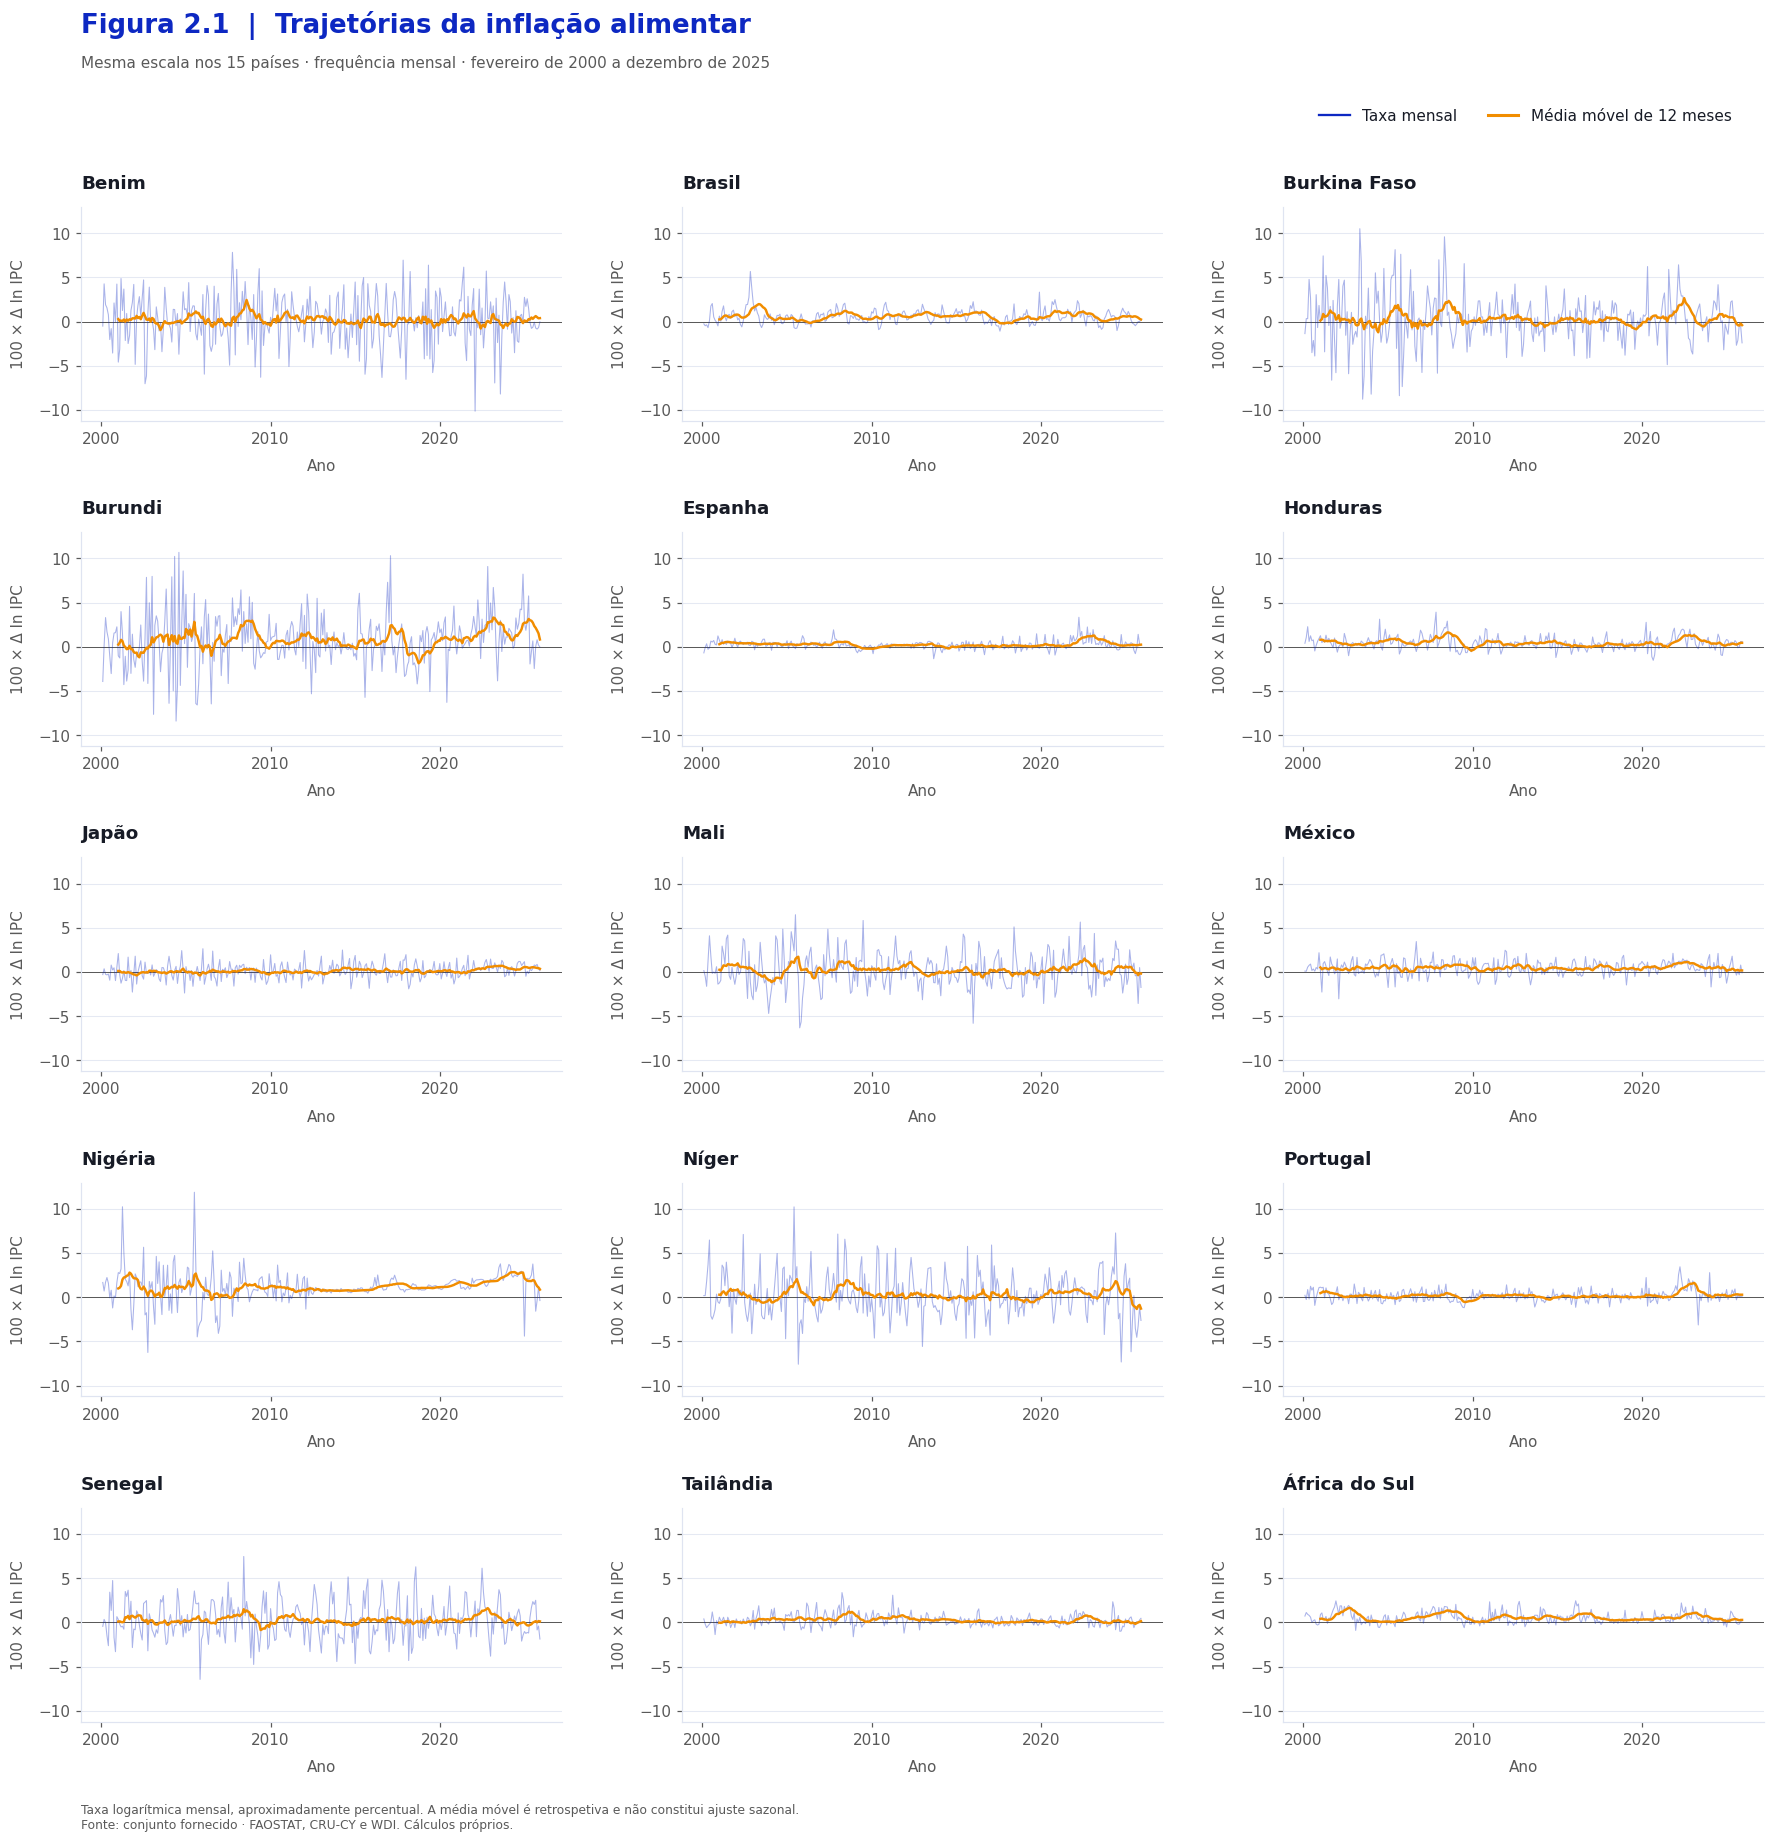

In [4]:
trajetorias_por_pais(dados, graficos)

medias = dados.groupby("pais")[Y].mean().sort_values()
nota(
    "Diagnóstico · heterogeneidade nacional",
    f"A média mais baixa pertence a {medias.index[0]} ({pt(medias.iloc[0])}) "
    f"e a mais elevada a {medias.index[-1]} ({pt(medias.iloc[-1])}). "
    "As trajetórias revelam também diferenças na amplitude e persistência dos picos. "
    "Uma única média global não descreve a experiência de todos os países.",
)

## 3. Distribuições nacionais

As caixas mostram Q1, mediana e Q3; os bigodes seguem a regra de 1,5 × IQR. O ponto azul é a média. Os pontos exteriores são omitidos apenas do gráfico: permanecem no painel e nas estatísticas. As caixas não são intervalos de confiança.

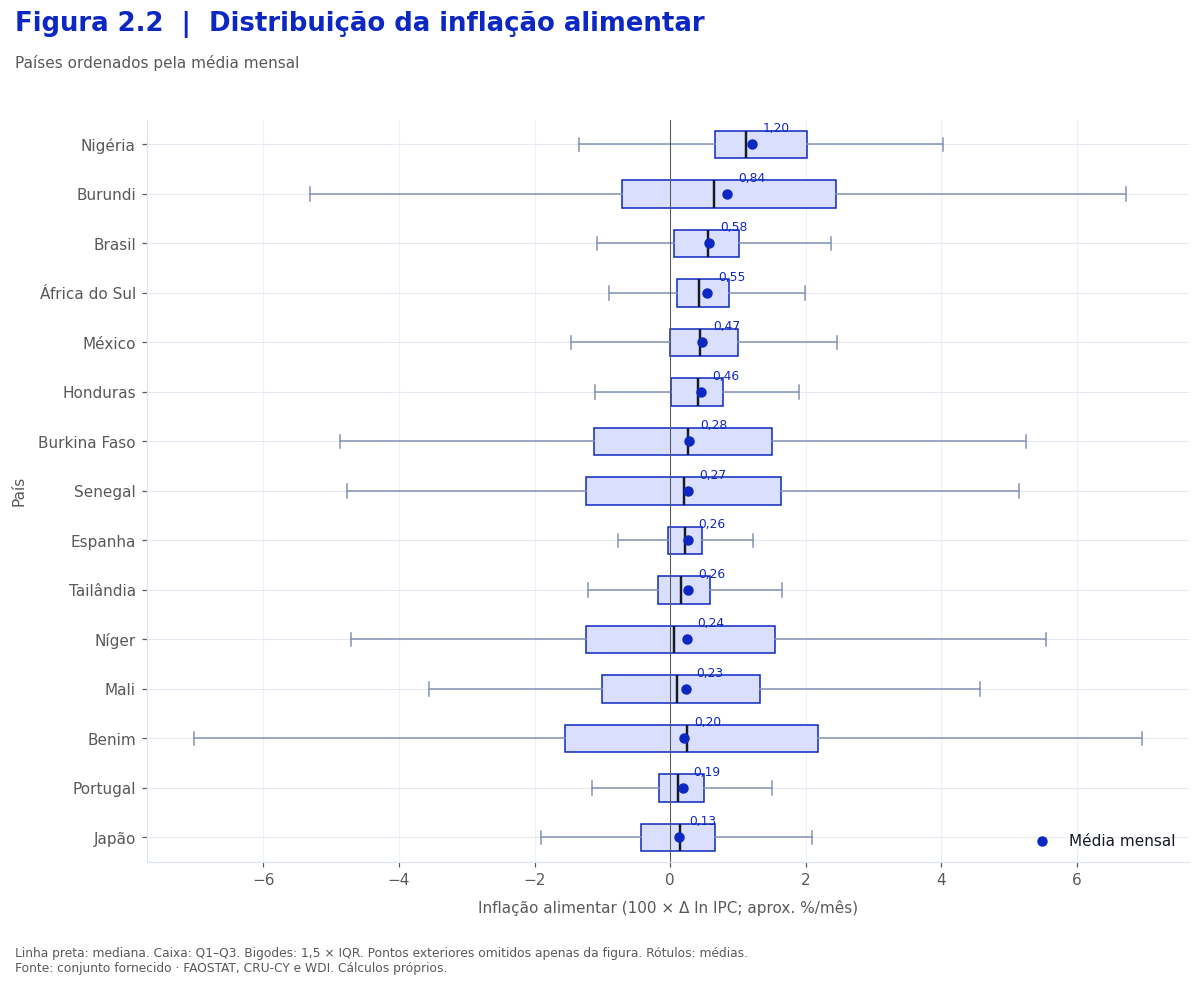

In [5]:
distribuicoes_nacionais(dados, graficos)

## 4. Evolução da média transversal

Comparam-se a média e a mediana dos países em cada mês. Os países não são ponderados pela população ou despesa alimentar: esta agregação não é uma taxa oficial de inflação mundial.

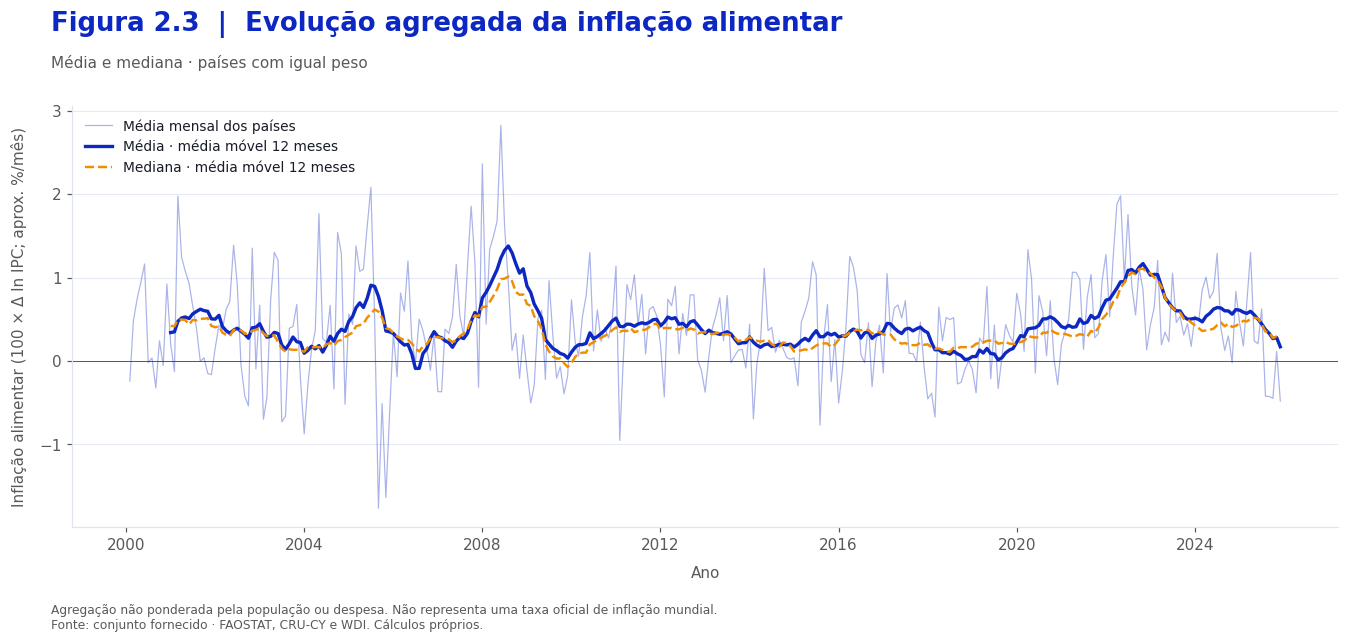

In [6]:
mensal = evolucao_agregada(dados)
evolucao_da_media(mensal, graficos)
csv(mensal.reset_index(), tabelas / "03_evolucao_agregada.csv")

pico = mensal["mean"].idxmax()
nota(
    "Diagnóstico · maior valor agregado",
    f"O maior valor da média transversal ocorre em {pico:%m/%Y}: "
    f'{pt(mensal.loc[pico, "mean"])}. A mediana reduz a influência de poucos países extremos. '
    "A coincidência temporal será examinada no notebook 03; este pico não identifica, por si só, a causa do movimento.",
)

## 5. Variabilidade entre e dentro dos países

**Entre:** desvio padrão das 15 médias nacionais. **Dentro:** desvio padrão dos desvios face à média do respetivo país. Os denominadores são diferentes; estas medidas não são parcelas aditivas de variância. Cada painel da figura usa a unidade indicada no seu eixo.

Variável,Unidade,DP total,DP entre médias,DP dentro
Inflação alimentar,100 × Δ ln IPC; aprox. %/mês,"1,782","0,291","1,760"
Anomalia térmica,°C,"0,694","0,072","0,691"
Défice hídrico de 3 meses,desvios padrão,"0,935","0,110","0,929"
Log PIB real por habitante (t−1),log natural,"1,234","1,272","0,116"
Peso agrícola no PIB (t−1),pontos percentuais do PIB,"12,978","13,242","2,176"
Calor × log PIB,°C × log PIB,"6,534","0,823","6,485"
Calor × peso agrícola,°C × p.p. do PIB,"12,797","1,768","12,682"


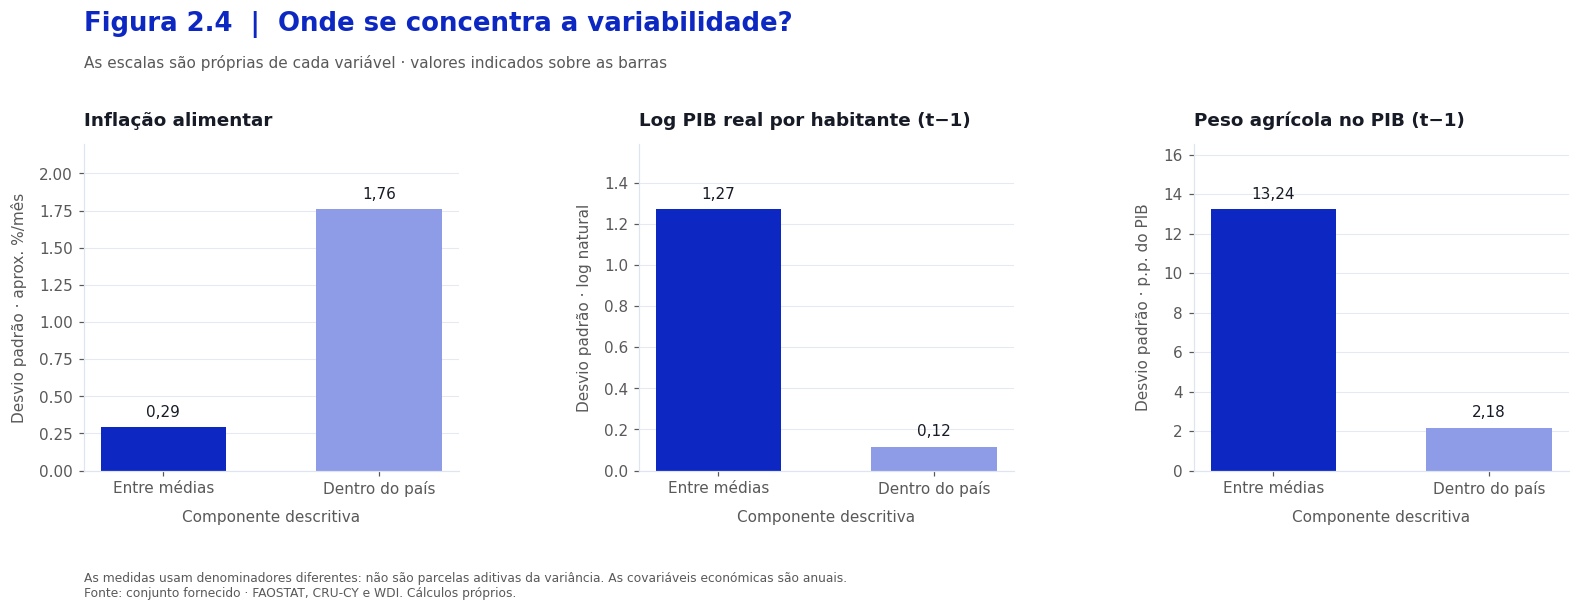

In [7]:
variacao = decompor_dispersao(dados, VARS)
tabela(variacao.drop(columns="coluna"), "Tabela 2.2 · Variabilidade entre e dentro")
csv(variacao, tabelas / "04_variabilidade_entre_dentro.csv")
dispersao_entre_dentro(variacao, graficos)

In [8]:
nota(
    "Diagnóstico · consequências para os modelos",
    "A inflação varia sobretudo ao longo do tempo dentro dos países. O PIB e o peso agrícola "
    "apresentam diferenças importantes entre países. Modelos com efeitos fixos nacionais "
    "identificam os coeficientes apenas a partir da variação dentro do país, mais limitada "
    "nas covariáveis anuais. As observações económicas repetidas não são medições mensais independentes.",
)

## 6. Evolução das anomalias térmicas

As células representam médias anuais de anomalias mensais face à referência 1991–2020, calculada por país e mês. Fevereiro–dezembro de 2000 contém 11 meses; os outros anos contêm 12. Médias nacionais e anuais podem ocultar extremos locais.

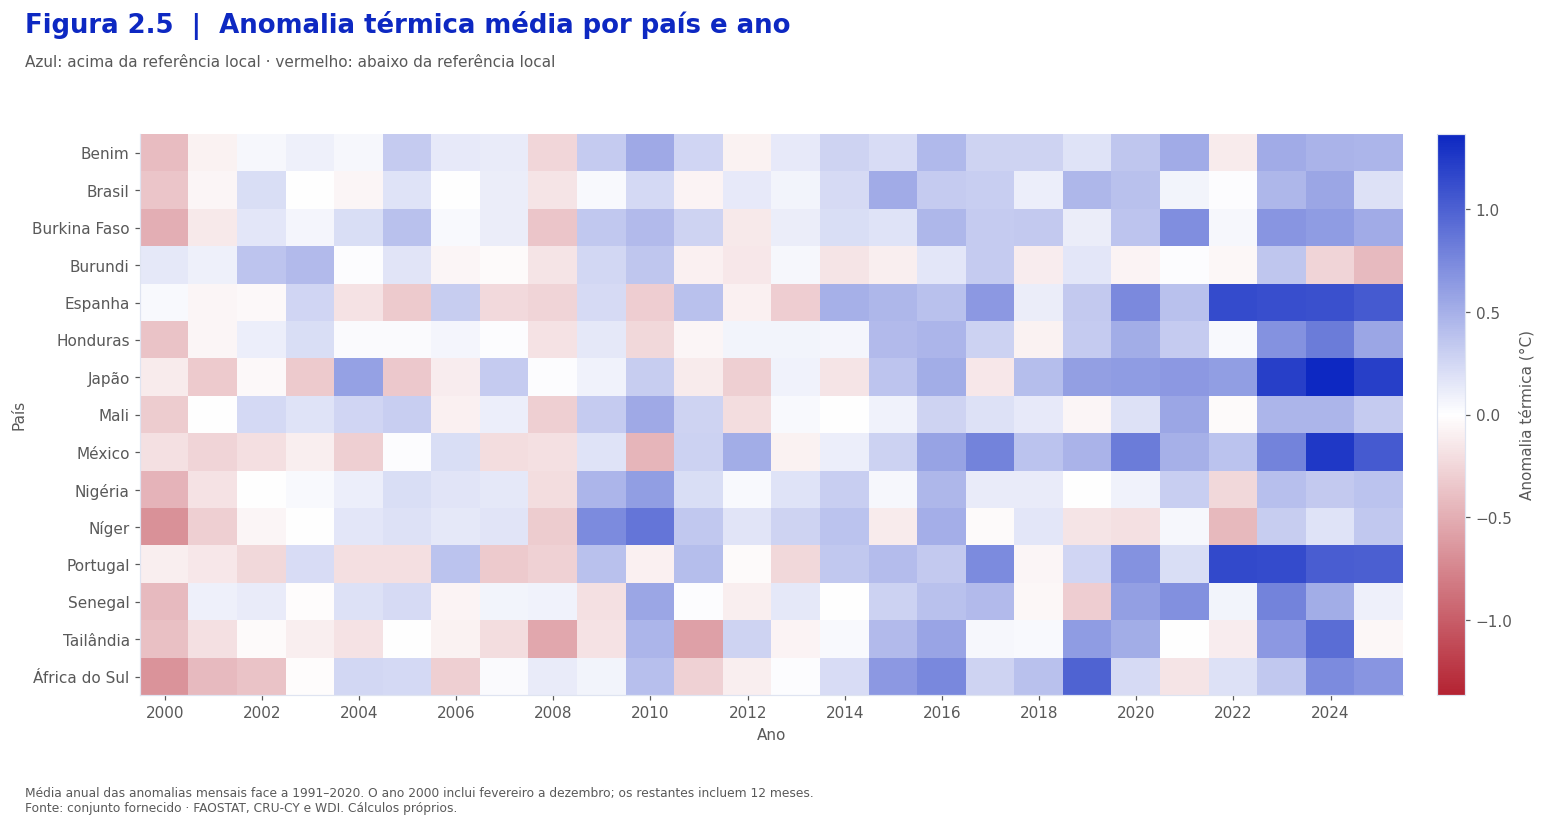

In [9]:
anual = anomalias_anuais(dados)
mapa_anomalias(anual, graficos)
csv(anual.reset_index(), tabelas / "05_anomalias_anuais.csv")

## 7. Diagnóstico e alterações recomendadas

1. **Heterogeneidade:** incluir efeitos de país na comparação dos modelos e distinguir informação entre países de variação dentro do país.
2. **Calendário:** investigar sazonalidade e choques comuns antes de atribuir associações às covariáveis climáticas.
3. **Extremos:** manter a análise principal integral, verificar a transformação e apresentar uma sensibilidade separada.

O notebook 03 quantifica estes problemas e apresenta uma lista de alterações propostas, com evidência, prioridade e critérios de verificação.